# Automatic step climbs during cruise

Compare fuel-optimal profiles with and without automatic step climbs for an A320 flying from Amsterdam (EHAM) to Athens (LGAV) in still air. Each pair uses the same route, starting mass (70,000 kg), and number of mesh intervals. The ordinary profile uses the optimizer’s standard cruise constraints.

Wall times cover each `trajectory()` call, including physical validation. Setup and plotting are outside the timer.

In [1]:
from time import perf_counter

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import opentop
from opentop.plotting import apply_publication_style

apply_publication_style()

## Complete flight

Use 40 intervals with 13 assigned to initial climb and 13 to final descent. The step-climb option applies during cruise.

In [2]:
def compare_profiles(phase, nodes, **options):
    runs = {}
    for label, step_climb in (("Step climb", True), ("Ordinary", False)):
        optimizer = phase("A320", "EHAM", "LGAV", m0=70_000)
        optimizer.setup(nodes=nodes)
        started = perf_counter()
        result = optimizer.trajectory(
            step_climb=step_climb, result_object=True, **options
        )
        elapsed = perf_counter() - started
        if not result.success:
            raise RuntimeError(f"{phase.__name__} ({label}): {result.status}")
        runs[label] = result.df
        summary = f"**{label}** — {elapsed:.2f} s ({result.status})"
        if step_climb:
            steps = optimizer.step_climb_diagnostics
            rates = ", ".join(f"{v:.0f}" for v in steps["amplitudes_fpm"])
            summary += f". Selected {steps['step_count']} of {steps['capacity']} slots."
            summary += f" Sustained rates by slot: {rates} ft/min."
        display(Markdown(summary))
    return runs


climb_intervals = descent_intervals = 13
flights = compare_profiles(
    opentop.CompleteFlight,
    40,
    climb_nodes=climb_intervals,
    descent_nodes=descent_intervals,
)

**Step climb** — 24.22 s (Solve_Succeeded). Selected 2 of 2 slots. Sustained rates by slot: 304, 382 ft/min.

**Ordinary** — 65.13 s (Solve_Succeeded)

During cruise, each step-climb slot can ramp up to a sustained climb rate and return to level flight. A zero sustained rate leaves the slot level.

## Flight profile

The upper panel uses each flight’s actual elapsed time. In the lower panels, the ordinary cruise starts and ends at the same plotted times as the step-climb cruise. Its time axis is stretched uniformly between those points to compare the profiles. Altitudes and vertical rates retain their optimized values.

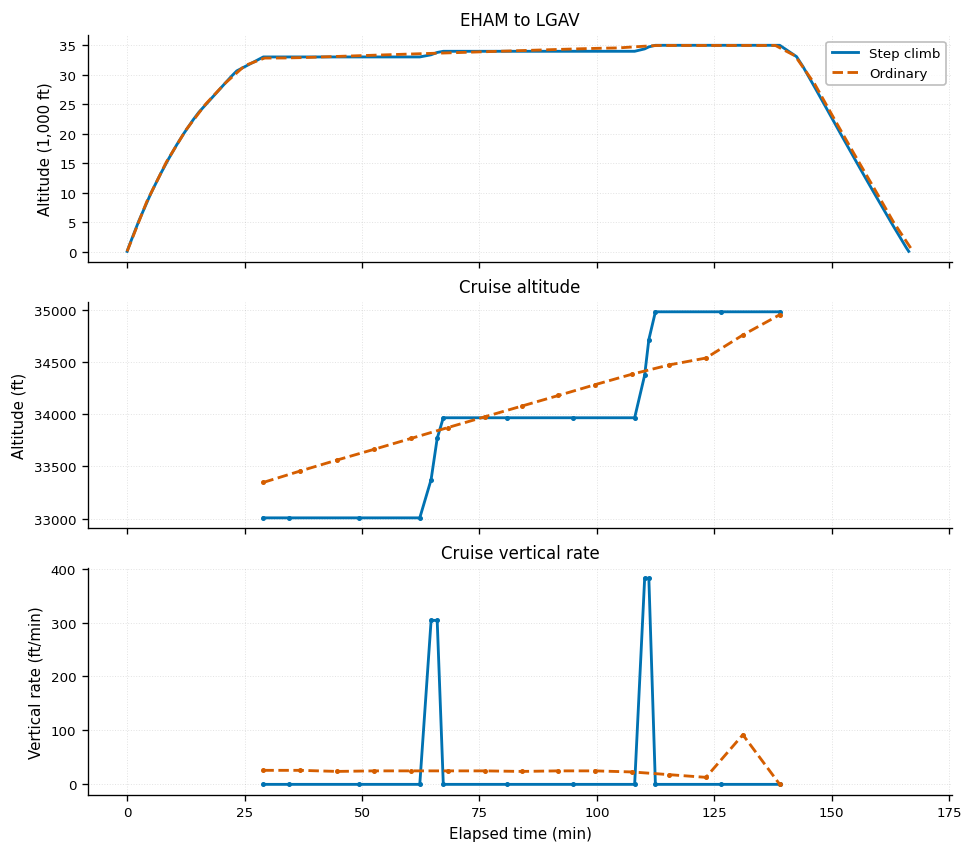

In [3]:
styles = {
    "Step climb": {"color": "C0", "linestyle": "-"},
    "Ordinary": {"color": "C1", "linestyle": "--"},
}


def plot_cruise(altitude, rate, minutes, cruise, label):
    style = styles[label]
    altitude.plot(minutes, cruise["altitude"], marker=".", label=label, **style)
    rate.plot(minutes, cruise["vertical_rate"], marker=".", label=label, **style)


fig, (profile, altitude, rate) = plt.subplots(
    3, 1, figsize=(8, 7), sharex=True, layout="constrained"
)
step_flight = flights["Step climb"]
step_minutes = (step_flight["ts"] - step_flight["ts"].iloc[0]) / 60
step_start = step_minutes.iloc[climb_intervals]
step_end = step_minutes.iloc[-descent_intervals - 1]

for label, flight in flights.items():
    minutes = (flight["ts"] - flight["ts"].iloc[0]) / 60
    profile.plot(minutes, flight["altitude"] / 1_000, label=label, **styles[label])
    cruise_nodes = slice(climb_intervals, len(flight) - descent_intervals)
    cruise_minutes = minutes.iloc[cruise_nodes]
    if label == "Ordinary":
        progress = (cruise_minutes - cruise_minutes.iloc[0]) / (
            cruise_minutes.iloc[-1] - cruise_minutes.iloc[0]
        )
        cruise_minutes = step_start + progress * (step_end - step_start)
    plot_cruise(altitude, rate, cruise_minutes, flight.iloc[cruise_nodes], label)

profile.set(title="EHAM to LGAV", ylabel="Altitude (1,000 ft)")
profile.legend()
altitude.set(title="Cruise altitude", ylabel="Altitude (ft)")
altitude.ticklabel_format(axis="y", style="plain", useOffset=False)
rate.set(
    title="Cruise vertical rate",
    ylabel="Vertical rate (ft/min)",
    xlabel="Elapsed time (min)",
)
for axis in (profile, altitude, rate):
    axis.grid(True)
plt.show()

## Cruise only

Optimize the same route entirely at cruise altitude with 30 intervals. Here 70,000 kg is the mass at cruise entry. This is a separate optimization, so its cruise profile can differ from the cruise segment of the complete flight.

In [4]:
cruise_flights = compare_profiles(opentop.Cruise, 30)

**Step climb** — 20.30 s (Solve_Succeeded). Selected 3 of 3 slots. Sustained rates by slot: 125, 117, 236 ft/min.

**Ordinary** — 26.90 s (Solve_Succeeded)

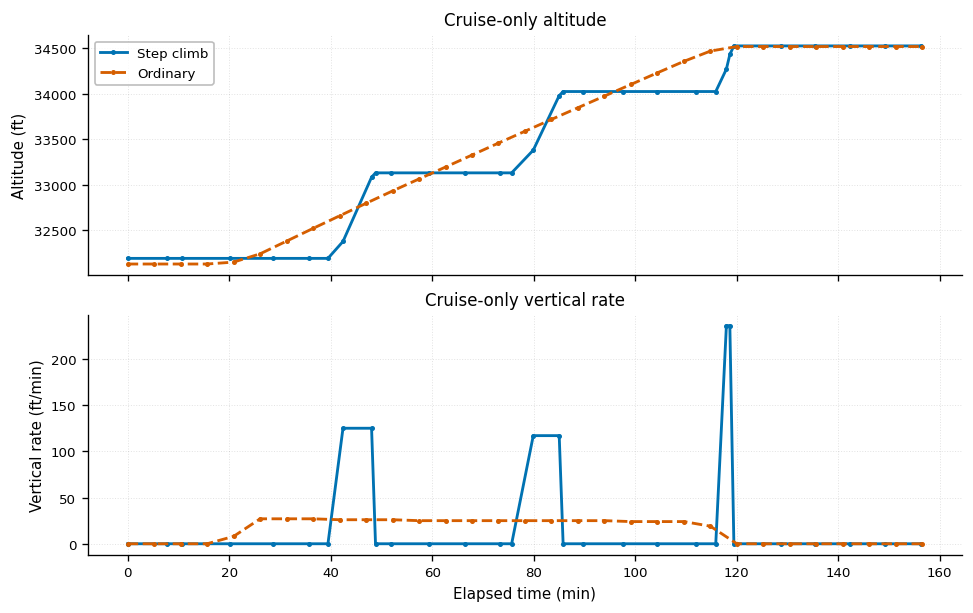

In [5]:
fig, (altitude, rate) = plt.subplots(
    2, 1, figsize=(8, 5), sharex=True, layout="constrained"
)
for label, cruise in cruise_flights.items():
    minutes = (cruise["ts"] - cruise["ts"].iloc[0]) / 60
    plot_cruise(altitude, rate, minutes, cruise, label)

altitude.set(title="Cruise-only altitude", ylabel="Altitude (ft)")
altitude.ticklabel_format(axis="y", style="plain", useOffset=False)
altitude.legend()
rate.set(
    title="Cruise-only vertical rate",
    ylabel="Vertical rate (ft/min)",
    xlabel="Elapsed time (min)",
)
for axis in (altitude, rate):
    axis.grid(True)
plt.show()